In [20]:
# Importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as  sns 
import geopandas as gpd


# NAIROBI RAINFALL DATA

In [4]:
# loading the national rainfall dataset
rainfall_data = pd.read_csv("C:\\Users\\PC\\Flood-Monitoring-and-Risk-Predictor\\DATA\\ken-rainfall-subnat-full (1).csv")

In [5]:
# filter Nairobis datw using pcode KE047
Nairobi_rainfall_data = rainfall_data[rainfall_data['PCODE']=='KE047'].copy()

In [6]:
Nairobi_rainfall_data.head()

,date,adm_level,adm_id,PCODE,n_pixels,rfh,rfh_avg,r1h,r1h_avg,r3h,r3h_avg,rfq,r1q,r3q,version
4926,1981-01-01,1,51328,KE047,26.0,6.923077,19.192308,NaN,NaN,NaN,NaN,49.284576,NaN,NaN,final
4927,1981-01-11,1,51328,KE047,26.0,3.192308,21.137178,NaN,NaN,NaN,NaN,31.343504,NaN,NaN,final
4928,1981-01-21,1,51328,KE047,26.0,5.269231,18.716667,15.384616,59.046154,NaN,NaN,43.299637,31.828010,NaN,final
4929,1981-02-01,1,51328,KE047,26.0,3.307692,12.447435,11.769231,52.301280,NaN,NaN,47.615550,29.265017,NaN,final
4930,1981-02-11,1,51328,KE047,26.0,7.384615,16.676922,15.961538,47.841026,NaN,NaN,57.132720,39.669060,NaN,final


In [7]:
# Convert the date column to datetime format
Nairobi_rainfall_data['date']=pd.to_datetime(Nairobi_rainfall_data['date'])

In [9]:
# Filter the data from 2018 to present
Nairobi_rainfall_data = Nairobi_rainfall_data[
    Nairobi_rainfall_data['date'] >= '2018-01-01'
].copy() 

In [10]:
Nairobi_rainfall_data.head()

,date,adm_level,adm_id,PCODE,n_pixels,rfh,rfh_avg,r1h,r1h_avg,r3h,r3h_avg,rfq,r1q,r3q,version
6258,2018-01-01,1,51328,KE047,26.0,17.346153,19.192308,29.423077,79.662820,212.538450,290.24487,92.368835,40.659027,73.680690,final
6259,2018-01-11,1,51328,KE047,26.0,9.500000,21.137178,32.000000,75.401280,191.346160,294.71667,55.476536,46.019165,65.510590,final
6260,2018-01-21,1,51328,KE047,26.0,12.884615,18.716667,39.730766,59.046154,180.730770,290.29870,75.409480,69.841450,62.895900,final
6261,2018-02-01,1,51328,KE047,26.0,10.230769,12.447435,32.615383,52.301280,139.269240,251.28975,87.295170,65.644930,56.291462,final
6262,2018-02-11,1,51328,KE047,26.0,6.230769,16.676922,29.346153,47.841026,101.346146,220.49487,51.809800,64.999020,47.161224,final


In [11]:
# Handelling missing values
Nairobi_rainfall_data.isnull().sum()

date         0
adm_level    0
adm_id       0
PCODE        0
n_pixels     0
rfh          0
rfh_avg      0
r1h          0
r1h_avg      0
r3h          0
r3h_avg      0
rfq          0
r1q          0
r3q          0
version      0
dtype: int64

In [12]:
Nairobi_rainfall_data.columns

Index(['date', 'adm_level', 'adm_id', 'PCODE', 'n_pixels', 'rfh', 'rfh_avg',
       'r1h', 'r1h_avg', 'r3h', 'r3h_avg', 'rfq', 'r1q', 'r3q', 'version'],
      dtype='str')

In [14]:
# Dropping columns that are not needed for the analysis
columns_to_keep = ['date', 'PCODE', 'rfh', 'rfh_avg', 'r1h', 'r3h']
Nairobi_rainfall_data = Nairobi_rainfall_data[columns_to_keep]
columns_to_drop = [
    'adm_level', 
    'adm_id', 
    'n_pixels', 
    'r1h_avg', 
    'r3h_avg', 
    'rfq', 
    'r1q', 
    'r3q', 
    'version'
]
Nairobi_rainfall_data = Nairobi_rainfall_data.drop(columns=columns_to_drop, errors='ignore')

In [15]:
Nairobi_rainfall_data.head(5)

,date,PCODE,rfh,rfh_avg,r1h,r3h
6258,2018-01-01,KE047,17.346153,19.192308,29.423077,212.538450
6259,2018-01-11,KE047,9.500000,21.137178,32.000000,191.346160
6260,2018-01-21,KE047,12.884615,18.716667,39.730766,180.730770
6261,2018-02-01,KE047,10.230769,12.447435,32.615383,139.269240
6262,2018-02-11,KE047,6.230769,16.676922,29.346153,101.346146


In [16]:
# Renaming the columns for better understanding
Nairobi_rainfall_data = Nairobi_rainfall_data.rename(columns={
    'PCODE': 'county_pcode',
    'rfh': 'rainfall_mm',
    'rfh_avg': 'historical_avg_rainfall_mm',
    'r1h': 'rainfall_1month_cum_mm',
    'r3h': 'rainfall_3month_cum_mm'

})

In [17]:
Nairobi_rainfall_data.head()

,date,county_pcode,rainfall_mm,historical_avg_rainfall_mm,rainfall_1month_cum_mm,rainfall_3month_cum_mm
6258,2018-01-01,KE047,17.346153,19.192308,29.423077,212.538450
6259,2018-01-11,KE047,9.500000,21.137178,32.000000,191.346160
6260,2018-01-21,KE047,12.884615,18.716667,39.730766,180.730770
6261,2018-02-01,KE047,10.230769,12.447435,32.615383,139.269240
6262,2018-02-11,KE047,6.230769,16.676922,29.346153,101.346146


In [19]:
# Extract Month and Year from the date column
Nairobi_rainfall_data['year'] = Nairobi_rainfall_data['date'].dt.year
Nairobi_rainfall_data['month'] = Nairobi_rainfall_data['date'].dt.month

#  Extract Month Name (e.g., 'January', 'February', etc.)
Nairobi_rainfall_data['month_name'] = Nairobi_rainfall_data['date'].dt.strftime('%B')

month_order = [
    'January', 'February', 'March', 'April', 'May', 'June', 
    'July', 'August', 'September', 'October', 'November', 'December'
]
Nairobi_rainfall_data['month_name'] = pd.Categorical(
    Nairobi_rainfall_data['month_name'], 
    categories=month_order, 
    ordered=True
)
Nairobi_rainfall_data.head()

,date,county_pcode,rainfall_mm,historical_avg_rainfall_mm,rainfall_1month_cum_mm,rainfall_3month_cum_mm,year,month,month_name
6258,2018-01-01,KE047,17.346153,19.192308,29.423077,212.538450,2018,1,January
6259,2018-01-11,KE047,9.500000,21.137178,32.000000,191.346160,2018,1,January
6260,2018-01-21,KE047,12.884615,18.716667,39.730766,180.730770,2018,1,January
6261,2018-02-01,KE047,10.230769,12.447435,32.615383,139.269240,2018,2,February
6262,2018-02-11,KE047,6.230769,16.676922,29.346153,101.346146,2018,2,February


# EXPLORATORY DATA ANALYSIS
- EDA helps uncover underlying seasonal cycles,peak flood months and extreme weather spikes 

In [21]:
# Statistical summary of the rainfall data
Nairobi_rainfall_data.describe()

,date,rainfall_mm,historical_avg_rainfall_mm,rainfall_1month_cum_mm,rainfall_3month_cum_mm,year,month
count,310,310.000000,310.000000,310.000000,310.000000,310.000000,310.000000
mean,2022-04-16 13:09:40.645161,28.197270,23.071596,84.628536,255.595906,2021.819355,6.335484
min,2018-01-01 00:00:00,1.307692,2.826923,4.730769,24.846153,2018.000000,1.000000
25%,2020-02-23 06:00:00,4.817308,6.009295,23.519231,103.932695,2020.000000,3.000000
50%,2022-04-16 00:00:00,13.365385,18.954487,47.884616,211.557685,2022.000000,6.000000
75%,2024-06-08 12:00:00,34.663463,37.166668,123.990375,334.230760,2024.000000,9.000000
max,2026-08-01 00:00:00,280.500000,61.614100,561.000000,925.230800,2026.000000,12.000000
std,NaN,37.954113,17.613999,89.682636,189.591268,2.496524,3.432714


### Summary of Nairobi Rainfall Data & Insights
From reviewing the statistical summary of my Nairobi dataset, several key patterns emerge:
* **Timeframe:** The dataset covers an 8 year period from 2018 through 2026.
* **Rainfall Levels:** The average recorded rainfall sits at around **28.2 mm**, but extreme weather events spike as high as **280.5 mm**, representing severe storms.
* **Ground Saturation:** The 1-month and 3-month cumulative rainfall columns (peaking up to **561 mm** and **925 mm** respectively) successfully capture long term moisture accumulation, which is critical since urban floods in Nairobi typically occur when soil and drainage systems remain saturated over extended periods.

C:\Users\PC\AppData\Local\Temp\ipykernel_21908\4180444146.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='month_name', y='rainfall_mm', data=monthly_rainfall, palette='Blues_d')


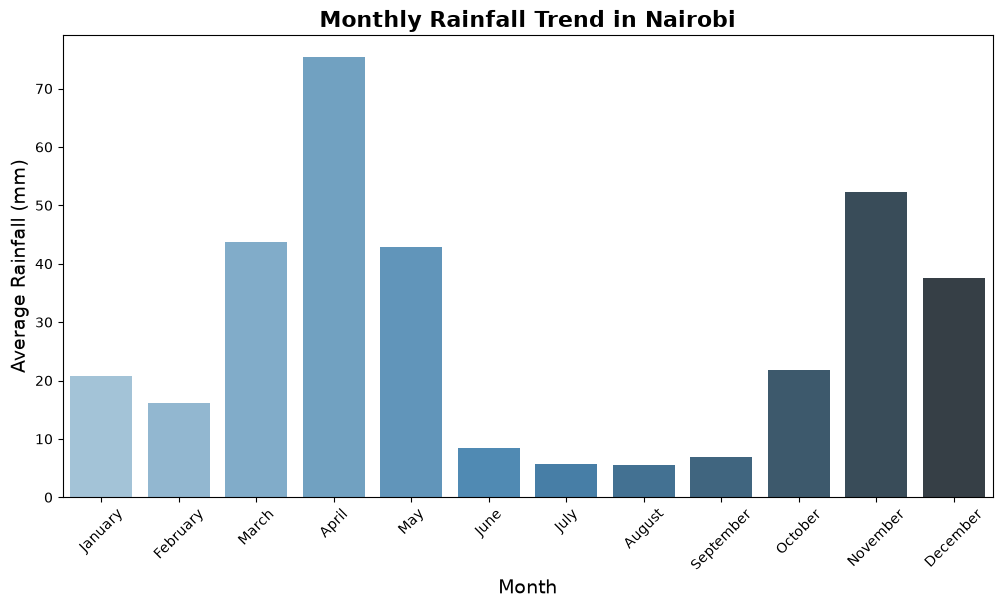

In [25]:
# Monthly trend Analysis(Aggregating the rainfall by month)
monthly_rainfall = Nairobi_rainfall_data.groupby('month_name')['rainfall_mm'].mean().reset_index()

# Plotting the monthly rainfall trend
plt.figure(figsize=(12, 6))
sns.barplot(x='month_name', y='rainfall_mm', data=monthly_rainfall, palette='Blues_d')
plt.title('Monthly Rainfall Trend in Nairobi',fontsize=16,fontweight='bold')
plt.xlabel('Month',fontsize=14)
plt.ylabel('Average Rainfall (mm)',fontsize=14)
plt.xticks(rotation=45)
plt.show()

- The chart shows the combined averaged data across the entire 8 year period. It groups all the months together to reveal a seasonal trend.
### Interpretation of Monthly Rainfall Trends
Looking at the monthly bar chart for Nairobi, clear seasonal patterns emerge from my 8 year dataset (2018–2026):
* **The "Long Rains" Season:** Rainfall peaks sharply between March and May, with **April** receiving the highest average rainfall (surpassing 75 mm). This represents Nairobi's primary wet season.
* **The "Short Rains" Season:** A second, smaller peak occurs later in the year from October through December, peaking in **November** at over 50 mm.
* **The Dry Season:** June, July, August, and September experience a prolonged dry spell, where average monthly rainfall drops significantly below 10 mm. This cyclical pattern directly informs when flood risks are highest during the year.

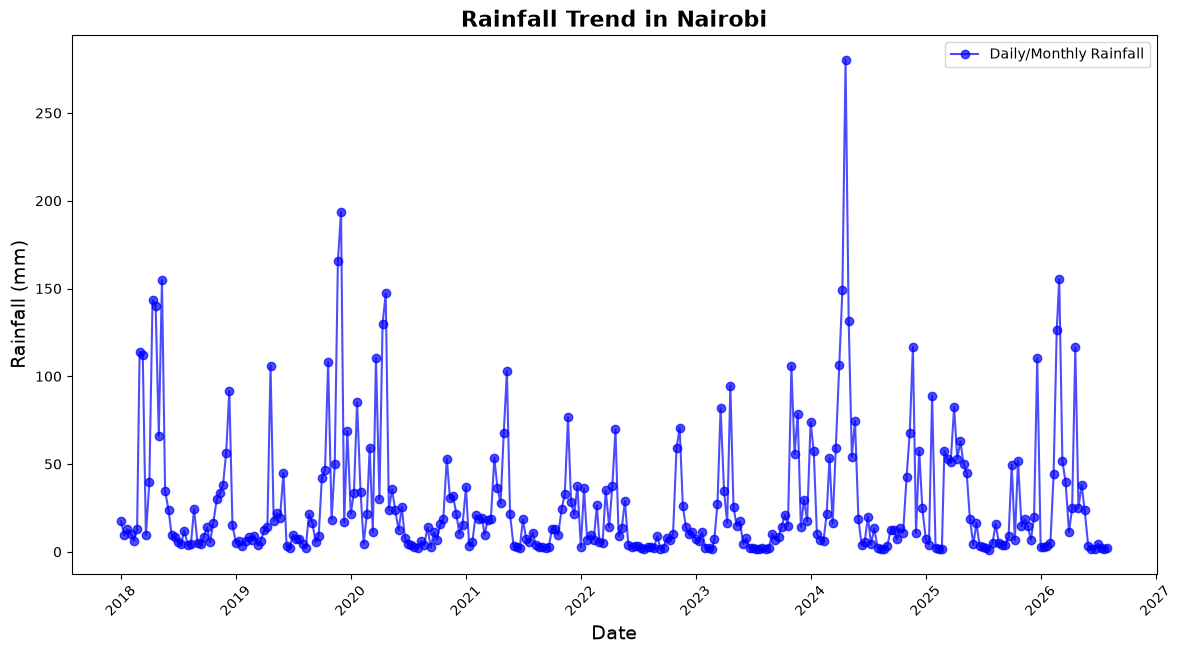

In [26]:
# Time series Trend over Time
plt.figure(figsize=(14, 7))
plt.plot(Nairobi_rainfall_data['date'], Nairobi_rainfall_data['rainfall_mm'], marker='o', linestyle='-', color='b',alpha=0.7,label='Daily/Monthly Rainfall')

plt.title('Rainfall Trend in Nairobi', fontsize=16, fontweight='bold')
plt.xlabel('Date', fontsize=14)
plt.ylabel('Rainfall (mm)', fontsize=14)
plt.xticks(rotation=45)
plt.legend()

plt.show()

### Interpretation of Nairobi Rainfall Trend Over Time
Looking at the time-series plot spanning from 2018 to 2026, I can observe the following patterns:
* **Cyclical Consistency:** The rainfall spikes repeat regularly every year, clearly mapping out Nairobi's alternating wet and dry seasons over time.
* **Extreme Storm Outliers:** While most periods stay at baseline levels, certain years experience massive surges. Notably, **2024** features a massive peak shooting past 250 mm, which likely highlights a severe historical flood event.
* **Variability:** The intensity of the rainy seasons fluctuates year on year, showing that some years experience much heavier cumulative precipitation than others.

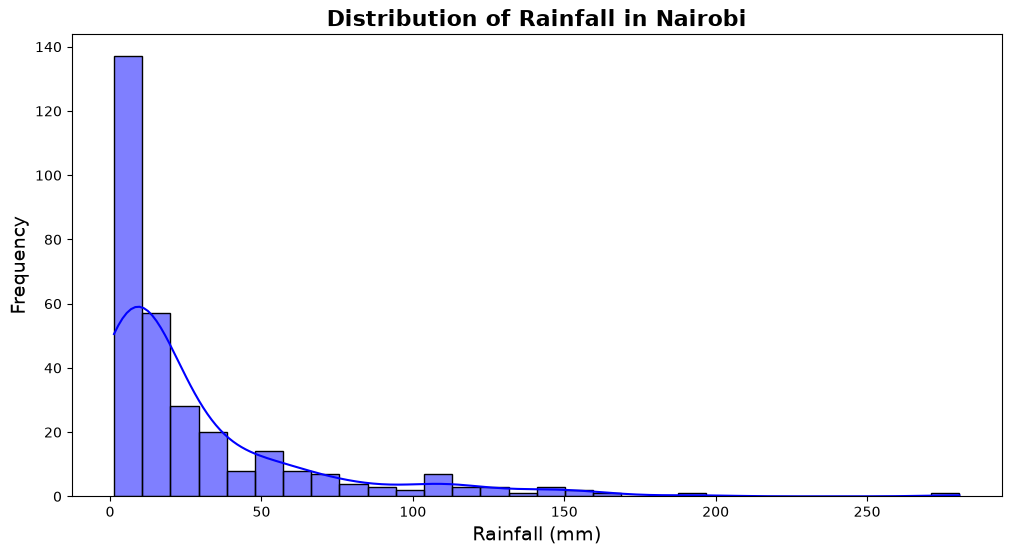

In [27]:
# Distribution Plot(Checking for extremes and outliers)
plt.figure(figsize=(12, 6))
sns.histplot(Nairobi_rainfall_data['rainfall_mm'], bins=30, kde=True, color='blue')
plt.title('Distribution of Rainfall in Nairobi', fontsize=16, fontweight='bold')
plt.xlabel('Rainfall (mm)', fontsize=14)
plt.ylabel('Frequency', fontsize=14)
plt.show()

### Interpretation of Rainfall Distribution
Looking at the histogram and KDE (Kernel Density Estimate) curve for Nairobi's rainfall across the 8-year dataset (2018–2026):
* **Right-Skewed Distribution:** The data is heavily right-skewed, meaning that most recorded intervals experience relatively low rainfall amounts (clustered heavily between 0 and 25 mm).
* **Fequency of Extremes:** Moderate to heavy rainfall values occur much less frequently. 
* **Outlier Tail:** The long tail stretching out toward 280 mm highlights rare, extreme storm events—which are critical outliers that will help my machine learning model differentiate standard weather from severe, flood-inducing conditions.

C:\Users\PC\AppData\Local\Temp\ipykernel_21908\3972704859.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='month_name', y='rainfall_mm', data=Nairobi_rainfall_data, palette='Blues')


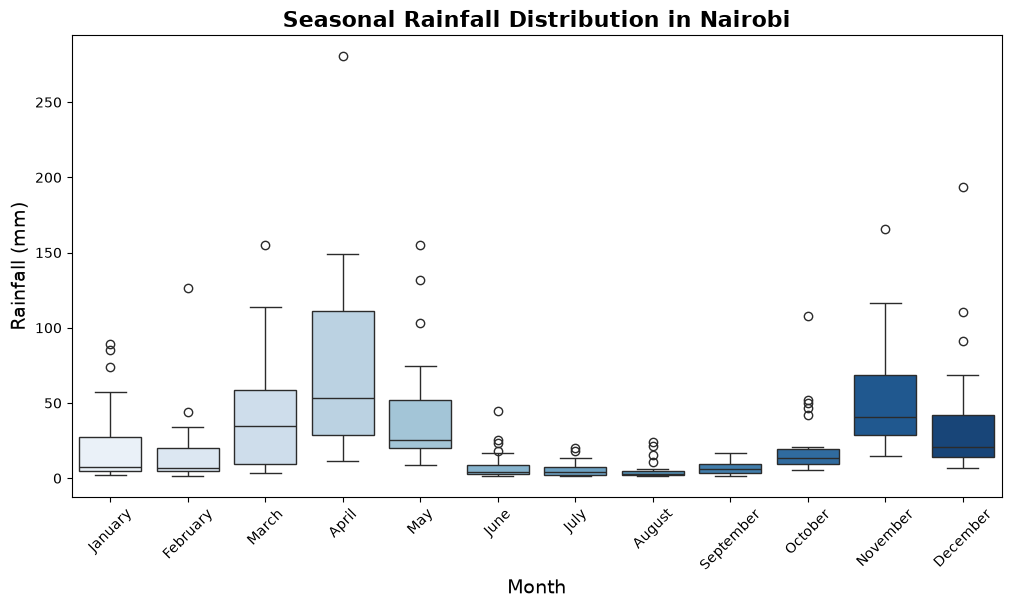

In [29]:
# Seasonal Box Plot (Year over Year comparison)
plt.figure(figsize=(12, 6))
sns.boxplot(x='month_name', y='rainfall_mm', data=Nairobi_rainfall_data, palette='Blues')
plt.title('Seasonal Rainfall Distribution in Nairobi', fontsize=16, fontweight='bold')
plt.xlabel('Month', fontsize=14)
plt.ylabel('Rainfall (mm)', fontsize=14)
plt.xticks(rotation=45)
plt.show()

### Interpretation of Seasonal Rainfall Distribution (Box Plot)
Analyzing the distribution and spread of monthly rainfall across the 8 year dataset (2018–2026):
* **Median and Spread:** April shows the highest median rainfall and the widest interquartile range, indicating both heavy and highly variable precipitation during the peak of the long rains. November follows as the second most intense wet month.
* **Consistency of Dry Months:** June through September display extremely tight boxes and low medians near zero, confirming a very stable and pronounced dry season.
* **Outliers and Extreme Events:** Several months particularly April, May, October, and December feature notable outlier points (represented as circles above the whiskers), highlighting anomalous, high intensity storm events that deviate significantly from typical monthly norms.

In [ ]:
==